# Model D — Failure Category Classifier (multilabel)

**Project:** Startup Idea Failure Prediction and Recommendation System  
**Purpose:** Given text describing a startup, estimate which *failure-risk categories* may apply (several can apply at once).

## Target definition (read this first)
| Item | Definition |
|---|---|
| Task | Multilabel text classification, 8 categories |
| Categories | market demand · funding/cash-flow · competition/differentiation · unit economics/pricing · customer acquisition/retention · team/operations · weak business model · product-market fit |
| Training data | `startup-failures.csv` — 1,000+ **already-failed** startups with a `failure_reason` and a `lesson` narrative |
| Training text | `failure_reason` + `lesson` combined (as chosen) |
| Labels | **Weak labels** generated by documented keyword/regex rules (no human-annotated categories exist in the dataset) |
| Model | Sentence-embedding encoder (frozen; offline TF-IDF+SVD fallback if the encoder cannot be loaded) + One-vs-Rest Logistic Regression, per-class Platt calibration and per-class thresholds |
| Output | Per-category probability, predicted flag, evidence sentence, matched keywords, similar historical failures |

## Limitations (also saved in the model card)
1. **Labels are rule-derived, not human-verified.** Metrics measure agreement with the rules, *not* ground truth. A human-review sample is exported for auditing.
2. **Circularity risk:** the rules are keyword-based, so a classifier can look good just by recognising the keywords. This notebook therefore also evaluates on **keyword-masked text** to test whether the model generalises beyond the rule vocabulary.
3. **Domain shift:** training text is *post-mortem narratives of failed companies*. Real inputs will be *forward-looking idea descriptions*. Output must be read as "risk themes similar to those in past failures", **not** as confirmed causes.
4. **Survivorship / no negatives:** every row is a failure, so the model cannot say whether a startup will fail — that is Model A/B's job.
5. Rows matching no category (regulatory, macro, acqui-hire, etc.) are outside the 8-category taxonomy.

## 1. Import libraries and configuration

In [1]:
import os, re, json, warnings, platform, random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.calibration import calibration_curve
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, brier_score_loss, hamming_loss, accuracy_score,
                             multilabel_confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

# ---------------- CONFIG ----------------
RANDOM_STATE      = 42
TEST_SIZE         = 0.20
CV_FOLDS          = 5
MIN_POSITIVES     = 15          # a category needs >= this many positives in TRAIN to be modelled
EXCLUDE_UNLABELED = True        # rows matching none of the 8 categories are out-of-taxonomy -> excluded
USE_MASK_AUG      = True        # add keyword-masked copies of training rows (reduces keyword memorisation)
C_GRID            = [0.3, 1.0, 3.0, 10.0]
EMBED_MODEL       = "sentence-transformers/all-MiniLM-L6-v2"   # downloaded from Hugging Face if Internet is ON
EMBED_MODEL_LOCAL = None   # OPTIONAL: folder containing the encoder (modules.json) if you attached it as a Kaggle input
ENCODER_MODE      = "auto" # "auto": local copy -> Hugging Face -> offline LSA fallback | "sentence_transformer": strict (stop with an error if unavailable) | "lsa": force the offline encoder
LSA_DIM           = 256    # embedding size of the offline fallback encoder (TF-IDF -> truncated SVD)

INPUT_ROOT = Path("/kaggle/input")
_found = list(INPUT_ROOT.rglob("startup-failures.csv")) if INPUT_ROOT.exists() else []
DATA_PATH = Path(os.environ["MODEL_D_DATA"]) if "MODEL_D_DATA" in os.environ else (_found[0] if _found else None)
assert DATA_PATH is not None and DATA_PATH.exists(), "startup-failures.csv not found under /kaggle/input - attach the dataset."
OUT_DIR = Path(os.environ.get("MODEL_D_OUT", "/kaggle/working/model_d"))
OUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)
print("Data :", DATA_PATH)
print("Out  :", OUT_DIR)
print("Python", platform.python_version(), "| sklearn", sklearn.__version__)

Data : /kaggle/input/datasets/mananpatel7310/startup-failures/startup-failures.csv
Out  : /kaggle/working/model_d
Python 3.13.15 | sklearn 1.6.1


## 2. Load, clean and pre-process
Steps: normalise whitespace → drop duplicate startups (by `slug`, then identical text) → build the combined text → create a **company group key** (used so the same company never lands in both train and test) → sanity checks.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Raw shape:", df_raw.shape)
display(df_raw.head(3))
print(df_raw.isna().sum()[lambda s: s > 0])

Raw shape: (1028, 15)


,slug,name,founded,failed,country,industry,category,funding_raised_usd_millions,funding_raised_label,peak_valuation,employees_at_peak,failure_reason,investors,lesson,url
0,milkrun,MilkRun,2018.0,2023,Australia,Quick Commerce/Grocery,major,75.0,$75M,NaN,NaN,Unsustainable Unit Economics,"AirTree Ventures, Blackbird Ventures, Tiger Global, Grok Ventures",Sydney's quick-commerce darling raised AUD$75M+ then collapsed inside 18 months when capital tightened. Australian density couldn't supp...,https://ideaproof.io/failure/milkrun
1,send-au,Send,2020.0,2022,Australia,Quick Commerce/Grocery,notable,11.0,$11M,NaN,NaN,Quick-Commerce Collapse,"Atlassian co-founder Mike Cannon-Brookes (Grok), Folklore","Smaller Australian quick-commerce competitor that collapsed before MilkRun, signaling the entire category's unviability locally.",https://ideaproof.io/failure/send-au
2,metigy,Metigy,2015.0,2022,Australia,MarTech/AI,notable,28.0,$28M,NaN,NaN,Cash Burn & Founder Issues,"Cygnet Capital, Regal Funds, Five V Capital",Sydney AI-marketing platform raised AUD$28M then collapsed amid allegations the founder used company funds for personal property. A gove...,https://ideaproof.io/failure/metigy


founded                          8
country                         49
funding_raised_usd_millions    135
peak_valuation                 702
employees_at_peak              799
investors                       55
dtype: int64


In [3]:
df = df_raw.copy()
df = df.rename(columns={"failed": "failure_year"})          # in this file `failed` holds the failure YEAR

text_cols = ["name", "country", "industry", "category", "failure_reason", "lesson", "investors"]
for c in text_cols:
    df[c] = (df[c].fillna("").astype(str)
                  .str.replace(r"\s+", " ", regex=True).str.strip())

n0 = len(df)
df = df.drop_duplicates(subset="slug")
df["text"] = (df["failure_reason"].str.rstrip(" .") + ". " + df["lesson"]).str.strip(" .") + "."
df = df[(df["failure_reason"].str.len() + df["lesson"].str.len()) > 0]
df = df.drop_duplicates(subset="text").reset_index(drop=True)

df["group"] = df["name"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
df.loc[df["group"] == "", "group"] = df["slug"]
df["n_words"] = df["text"].str.split().str.len()

# sanity checks
bad_years = df[(df["founded"].notna()) & (df["failure_year"] < df["founded"])]
print(f"Rows: {n0} -> {len(df)} after de-duplication")
print("Unique company groups:", df["group"].nunique())
print("Rows where failure_year < founded:", len(bad_years))
print(df["n_words"].describe().round(1).to_string())

Rows: 1028 -> 1028 after de-duplication
Unique company groups: 1007
Rows where failure_year < founded: 0
count    1028.0
mean       29.1
std         9.4
min        16.0
25%        25.0
50%        27.0
75%        32.0
max       116.0


## 3. Data visualisation (raw data)

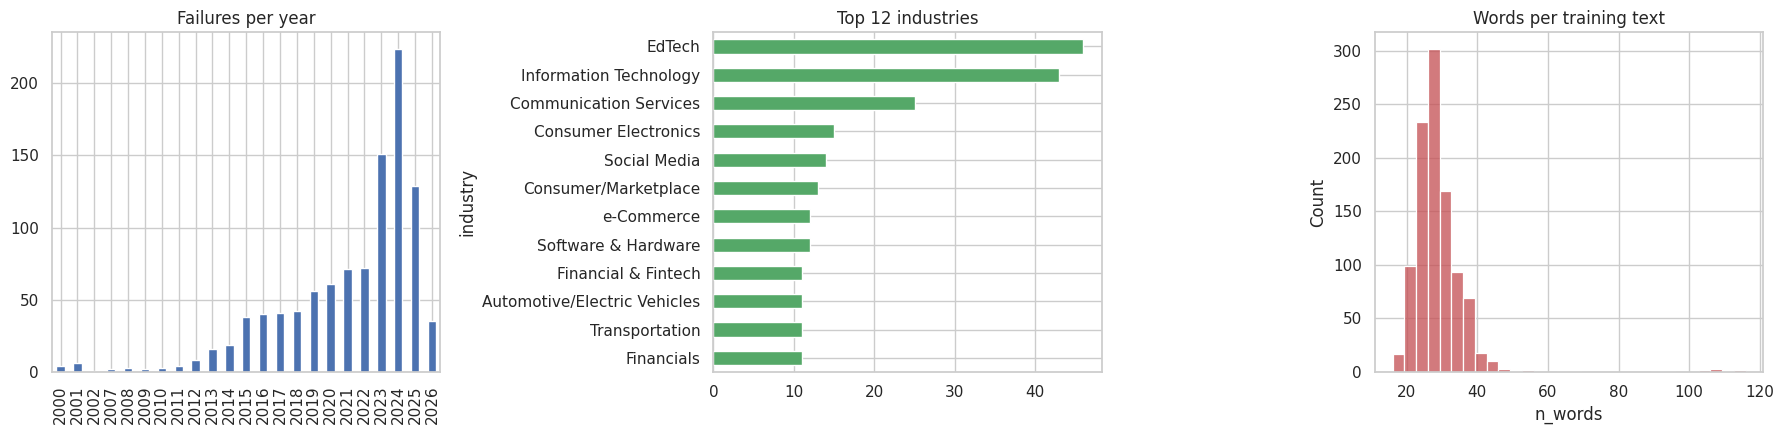

Top countries:
country
USA              355
China            168
India             86
United States     74
Unknown           57
UK                33
Germany           27
France            22


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
df["failure_year"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#4C72B0")
ax[0].set_title("Failures per year"); ax[0].set_xlabel("")
df["industry"].value_counts().head(12).iloc[::-1].plot(kind="barh", ax=ax[1], color="#55A868")
ax[1].set_title("Top 12 industries")
sns.histplot(df["n_words"], bins=30, ax=ax[2], color="#C44E52")
ax[2].set_title("Words per training text")
plt.tight_layout(); plt.show()

print("Top countries:"); print(df["country"].replace("", "Unknown").value_counts().head(8).to_string())

## 4. Label taxonomy and weak-label rules
The CSV has no category columns, so labels are produced by **regex rules** over `failure_reason + lesson`.  
These rules are the *documented definition of the target*. They are saved with the model and can be edited and re-run.

Design notes
- Bare `acquisition` is **not** a keyword (it would confuse "Acquired & Sunsetted" with customer acquisition).
- Fraud/governance/founder conflict → *team_operations*. Regulation, macro/interest-rate shocks and acqui-hires are **outside** the 8 categories and are tracked separately for coverage analysis only.
- A row can have several labels, and some categories overlap by nature (e.g. demand vs. product-market fit).- **Rule set v2:** bare topic words (*margin, pivot, business model, logistics, engagement, adoption, runway, debt…*) were replaced by **qualified problem phrases** (e.g. "thin margins", "had to pivot", "business model was unsustainable"), and `compet*` no longer fires after "no/without/few". A sanity-test cell checks that positives fire and neutral mentions do not.
- Rule **precision** is only known after a human audit (see the audit step); until then it is reported as *not measured*.


In [5]:
# Rule set v2: bare topic words (e.g. 'margin', 'pivot', 'business model', 'logistics', 'engagement') were replaced by
# qualified problem phrases, and 'compet*' no longer fires after 'no/without/few' (see the rule sanity tests below).
RULES = {
    'market_demand': [
        '(?:no|lack\\s+of|insufficient|weak|little|limited|low)\\s+(?:real\\s+|market\\s+|customer\\s+|consumer\\s+)?demand',
        'demand\\s+(?:collapse\\w*|evaporat\\w*|decline\\w*|drop\\w*|cool\\w*|never|fell|dried|was\\s+(?:weak|limited|insufficient))',
        'post-?covid\\s+demand|pandemic\\s+(?:tailwind|boom|demand)',
        'nobody\\s+(?:wanted|needed|would\\s+pay)|no\\s+one\\s+(?:wanted|needed|would\\s+pay)|no\\s+buyers|no\\s+market\\b',
        'market\\s+(?:was\\s+)?too\\s+small|small\\s+market|never\\s+materiali[sz]ed|market\\s+never',
        "didn'?t\\s+(?:need|want)\\s+it|no\\s+(?:real\\s+)?need\\b|\\bhype\\b|\\bfad\\b",
        'critical\\s+mass|cold[- ]start|consumer\\s+inertia|premature\\s+market|(?:bad|poor|wrong)\\s+(?:market\\s+)?timing|timing\\s+was\\s+(?:wrong|off|bad)|too\\s+niche|niche\\s+market\\s+(?:was\\s+)?too\\s+small|(?:failed|unable)\\s+to\\s+(?:reach|achieve)\\s+(?:scale|traction)',
    ],
    'funding_cashflow': [
        'cash[\\s-]*(?:burn\\w*|crunch|crisis|flow|shortage)|burn\\s+rate|ran\\s+out\\s+of\\s+(?:cash|money|runway|funding|capital)|run\\s+out\\s+of|(?:short|limited|insufficient|little)\\s+runway|runway\\s+(?:ran\\s+out|was\\s+(?:too\\s+)?short|ended)',
        "(?:could\\s*n[o']t|couldn'?t|unable\\s+to|failed\\s+to)\\s+(?:raise|secure\\s+(?:funding|financing|capital))",
        'funding\\s+(?:dried|freeze|winter|crunch|gap|shortfall|collapse)|capital\\s+(?:tightened|dried|crunch|markets)|tight(?:ened|ening)?\\s+capital|raise\\s+more\\s+capital|down\\s+round|credit\\s+crunch',
        "chapter\\s+(?:7|11)|bankrupt\\w*|insolven\\w*|liquidity\\s+(?:crisis|problems?|issues?|crunch|shortage)|(?:heavy|crushing|mounting|excessive)\\s+debt|debt\\s+(?:burden|load|pile|crisis|default)|too\\s+much\\s+debt|couldn'?t\\s+service|capital[- ]intensive|heavy\\s+capex|capex\\s+(?:burden|too\\s+high)",
    ],
    'competition_differentiation': [
        '(?<!\\bno\\s)(?<!\\bwithout\\s)(?<!\\bfew\\s)(?<!\\blittle\\s)compet\\w*|outspent|out-?spent|undercut\\w*|incumbent\\w*|commodit\\w*|winner[- ]take[- ]all|consolidat\\w*|crowded|copycat|\\bclones?\\b|differentiat\\w*|price\\s+war|squeezed\\s+out|asphyxiat\\w*|lost\\s+(?:market\\s+)?share|overtaken',
    ],
    'unit_economics_pricing': [
        "unit\\s+economics|economics\\s+(?:broke|broken|collapse\\w*|never|didn'?t|couldn'?t|unworkable)|(?:broken|bad|poor|negative|unsustainable|unviable)\\s+(?:\\w+\\s+)?economics",
        '(?:thin|low|negative|poor|shrinking|slim|razor-thin|eroding)\\s+margins?|margins?\\s+(?:were|was|too|eroded|collapsed|squeezed)|margin\\s+compression|unprofitab\\w*|(?:never|not|no)\\s+(?:\\w+\\s+){0,2}profitab\\w*|cost\\s+(?:structure|to\\s+serve|of\\s+(?:goods|delivery|fulfil\\w*))|\\bcogs\\b|too\\s+expensive|subsidi[sz]\\w*|(?:heavy|deep|steep|excessive|aggressive)\\s+discount\\w*',
        "(?:wrong|poor|bad|low|unsustainable)\\s+pricing|pricing\\s+(?:problems?|issues?|pressure|mistakes?)|price\\s+(?:cut|point|sensitiv\\w*)|flat[- ]fee\\s+(?:pricing\\s+)?(?:didn'?t|couldn'?t|failed)|couldn'?t\\s+cover|inventory\\s+(?:economics|costs?)",
    ],
    'acquisition_retention': [
        'customer\\s+acquisition|user\\s+acquisition|acquisition\\s+costs?|\\bcac\\b|cost\\s+of\\s+acquir\\w*|churn\\w*|retention|(?:failed|unable|struggl\\w*)\\s+to\\s+retain\\w*|retaining\\s+(?:users|customers)|re-?engage\\w*|(?:low|poor|weak|declining|falling)\\s+(?:user\\s+)?engagement|engagement\\s+(?:was\\s+)?(?:low|poor|weak|declin\\w*|dropp\\w*|fell)',
        'marketing\\s+(?:spend|costs?|budget)|paid\\s+(?:acquisition|marketing|growth)|ad\\s+spend|growth\\s+(?:stall\\w*|stagnat\\w*|plateau\\w*|slow\\w*)|stopped\\s+growing|(?:slow|stalled|stagnant|weak|poor)\\s+user\\s+growth|user\\s+growth\\s+(?:stalled|slowed|stagnated|plateaued)|(?:slow|low|poor|weak|limited)\\s+adoption|adoption\\s+(?:was\\s+)?(?:slow|low|poor|weak|stalled|limited)|long\\s+sales\\s+cycles?|(?:poor|weak|failed|flawed)\\s+(?:go-to-market|gtm)\\w*|(?:go-to-market|gtm)\\s+(?:failure|problems?|issues?)|lead\\s+generation|low\\s+conversion',
    ],
    'team_operations': [
        'founder\\w*\\s+(?:conflict|dispute|infight\\w*|issues?|exit\\w*|depart\\w*|fraud|convicted|left|clash\\w*|feud\\w*|misconduct|resign\\w*)|co-?founder\\s+(?:conflict|dispute|split|exit)|infighting|in-fighting',
        '(?:poor|weak|bad)\\s+(?:management|leadership|governance|execution)|mismanag\\w*|governance|misconduct|fraud\\w*|scandal|convicted|embezzl\\w*|executive\\s+(?:turnover|exodus|departure)',
        'premature\\s+scaling|scal(?:ed|ing)\\s+too\\s+(?:fast|quickly|early)|over-?expan\\w*|over-?hir\\w*|hired\\s+too|operational\\s+(?:issues?|problems?|complexity|failures?|challenges?)|execution\\s+(?:failure|problems?|issues?|risk)|logistics\\s+(?:problems?|issues?|challenges?|failures?|complexity)|supply\\s+chain\\s+(?:problems?|issues?|disruptions?|failures?|challenges?|complexity)|burn(?:ed|t)\\s+out|lack\\s+of\\s+(?:experience|expertise|technical)',
    ],
    'weak_business_model': [
        "(?:flawed|broken|weak|unproven|unsustainable|unclear|wrong|bad|poor|failed|fragile)\\s+(?:\\w+\\s+){0,2}(?:business|revenue)\\s+model|(?:business|revenue)\\s+model\\s+(?:was|were|never|didn'?t|couldn'?t|broke|failed|flawed|unproven|unsustainable|wasn'?t)|(?:unable|failed|struggl\\w*)\\s+to\\s+monetiz\\w*|monetiz\\w*\\s+(?:problems?|issues?|challenges?|failed|difficult\\w*)|no\\s+(?:clear\\s+)?(?:business|revenue)\\s+model",
        "(?:model|approach)\\s+(?:broke|collapsed?|unworkable|unproven|unsustainable|unviable|flawed|failed|never\\s+\\w+|couldn'?t|wasn'?t|didn'?t)",
        '(?:unsustainable|unviable|flawed|broken|unproven|unworkable|fragile)\\s+(?:\\w+\\s+){0,2}(?:model|approach|strategy)',
        "no\\s+(?:clear\\s+)?path\\s+to\\s+(?:profit\\w*|revenue|monetiz\\w*)|strategic\\s+(?:misalignment|drift|missteps?)|(?:forced|had|needed|failed|kept|continued)\\s+to\\s+pivot\\w*|pivot(?:ed)?\\s+(?:several|multiple|repeatedly|too\\s+many|again)|failed\\s+pivot|pivot\\w*\\s+(?:failed|didn'?t)|aggregator\\s+model|marketplace\\s+(?:model|liquidity)|never\\s+had\\s+liquidity|ad-subsidi[sz]ed|platform\\s+(?:dependence|dependency|risk)|(?:rent-to-own|flat-fee|cash-offer|home-visit)\\s+model",
    ],
    'product_market_fit': [
        "product[- ]market[- ]fit|\\bpmf\\b|never\\s+found\\s+(?:a\\s+)?(?:fit|market|niche)|(?:couldn'?t|failed\\s+to|never)\\s+find\\s+(?:a\\s+)?(?:fit|product[- ]market)",
        "solution\\s+in\\s+search|technology\\s+(?:in|looking)\\s+(?:search|for)|(?:wrong|unwanted|undifferentiated)\\s+product|product\\s+(?:never|didn'?t|wasn'?t|failed|couldn'?t)",
        'over-?promised|under-?delivered|never\\s+(?:produced|shipped|delivered|reached)\\s+(?:\\w+\\s+){0,3}(?:scale|market|commercial\\w*|customers)|too\\s+early|ahead\\s+of\\s+(?:its|their)\\s+time|premature\\s+(?:technology|product)',
        "(?:didn'?t|did\\s+not|failed\\s+to)\\s+solve|no\\s+(?:real\\s+)?problem|(?:product[- ]market|market|customer)\\s+mismatch|mismatch\\s+between\\s+(?:the\\s+)?(?:product|market|customers?)|(?:customers|users)\\s+(?:didn'?t|did\\s+not|never)\\s+(?:want|need|adopt|care)",
    ],
}

CATEGORY_NAMES = {
    "market_demand":               "Lack of market demand",
    "funding_cashflow":            "Funding and cash-flow problems",
    "competition_differentiation": "Strong competition or weak differentiation",
    "unit_economics_pricing":      "Poor unit economics or pricing",
    "acquisition_retention":       "Customer acquisition and retention difficulties",
    "team_operations":             "Team, skills, or operational problems",
    "weak_business_model":         "Weak business model",
    "product_market_fit":          "Product-market fit problems",
}
CLASSES = list(CATEGORY_NAMES)

# reporting-only themes (NOT model targets)
OTHER_THEMES = {
    "regulatory": r"regulat\w*|\bban(?:ned)?\b|crackdown|lawsuit|litigation|antitrust|\bfda\b|licen[sc]e",
    "macro_rates_covid": r"interest\s+rates?|\brates\b|inflation|recession|macro\w*|crypto\s+(?:winter|crash)|\bbtc\b|covid|pandemic|rate\s+hikes?",
    "acquired_or_acquihired": r"acqui-?hire\w*|acquired|sold\s+to|sunset\w*|merger|licen[sc]ed\s+tech",
}

RX = {k: re.compile("|".join(f"(?:{p})" for p in v), re.I) for k, v in RULES.items()}
ALL_RX = re.compile("|".join(f"(?:{p})" for v in RULES.values() for p in v), re.I)

def find_matches(text):
    """category -> sorted list of matched keyword strings"""
    return {k: sorted({m.group(0).lower() for m in rx.finditer(text)}) for k, rx in RX.items()}

def mask_keywords(text):
    """remove every rule-matched span; used to test generalisation beyond keywords"""
    t = re.sub(r"\s+", " ", ALL_RX.sub(" ", text)).strip()
    return t if len(t.split()) >= 3 else "unspecified"

In [6]:
# ---- rule sanity tests: positives must fire, neutral mentions must not (checks the rules behave as written) ----
TESTS = [
 ("competition_differentiation", True,  "Intense competition from incumbents crushed them."),
 ("competition_differentiation", False, "The founders had no competition in their niche."),
 ("weak_business_model",         True,  "The business model was unsustainable."),
 ("weak_business_model",         True,  "They had to pivot twice and never found a revenue model."),
 ("weak_business_model",         False, "They described their business model in the pitch deck."),
 ("weak_business_model",         False, "The team pivoted the roadmap toward enterprise features."),
 ("team_operations",             True,  "Founder conflict split the company."),
 ("team_operations",             True,  "Logistics problems overwhelmed the small team."),
 ("team_operations",             False, "They used a logistics partner for delivery."),
 ("acquisition_retention",       True,  "Customer acquisition costs soared and retention fell."),
 ("acquisition_retention",       False, "Early adoption by hospitals was celebrated at launch."),
 ("acquisition_retention",       False, "Engagement with the developer community was strong."),
 ("unit_economics_pricing",      True,  "Thin margins and heavy discounts made it unprofitable."),
 ("unit_economics_pricing",      False, "They discussed margins with investors."),
 ("product_market_fit",          True,  "They never found product-market fit."),
 ("product_market_fit",          False, "There was no mismatch in expectations between the founders."),
 ("funding_cashflow",            True,  "They ran out of runway and could not raise a bridge."),
 ("funding_cashflow",            False, "They discussed runway planning with advisors."),
 ("market_demand",               True,  "There was no real demand for the product."),
 ("market_demand",               False, "They planned the market launch carefully."),
]
bad = [(c, exp, t) for c, exp, t in TESTS if bool(find_matches(t)[c]) != exp]
assert not bad, f"Rule sanity tests failed: {bad}"
print(f"Rule sanity tests passed ({len(TESTS)} cases).")

Rule sanity tests passed (20 cases).


In [7]:
df["matches"] = df["text"].map(find_matches)
Y_all = pd.DataFrame({c: df["matches"].map(lambda m, c=c: int(len(m[c]) > 0)) for c in CLASSES})
df["n_labels"] = Y_all.sum(axis=1)

print("Label counts (all rows):"); print(Y_all.sum().to_string())
print(f"\nRows with no label: {(df.n_labels == 0).sum()} ({(df.n_labels == 0).mean():.1%})")
print("Labels per row:"); print(df["n_labels"].value_counts().sort_index().to_string())

Label counts (all rows):
market_demand                   72
funding_cashflow               166
competition_differentiation    255
unit_economics_pricing         251
acquisition_retention           50
team_operations                120
weak_business_model             81
product_market_fit              61

Rows with no label: 287 (27.9%)
Labels per row:
n_labels
0    287
1    484
2    203
3     50
4      4


## 5. Data visualisation (labels)

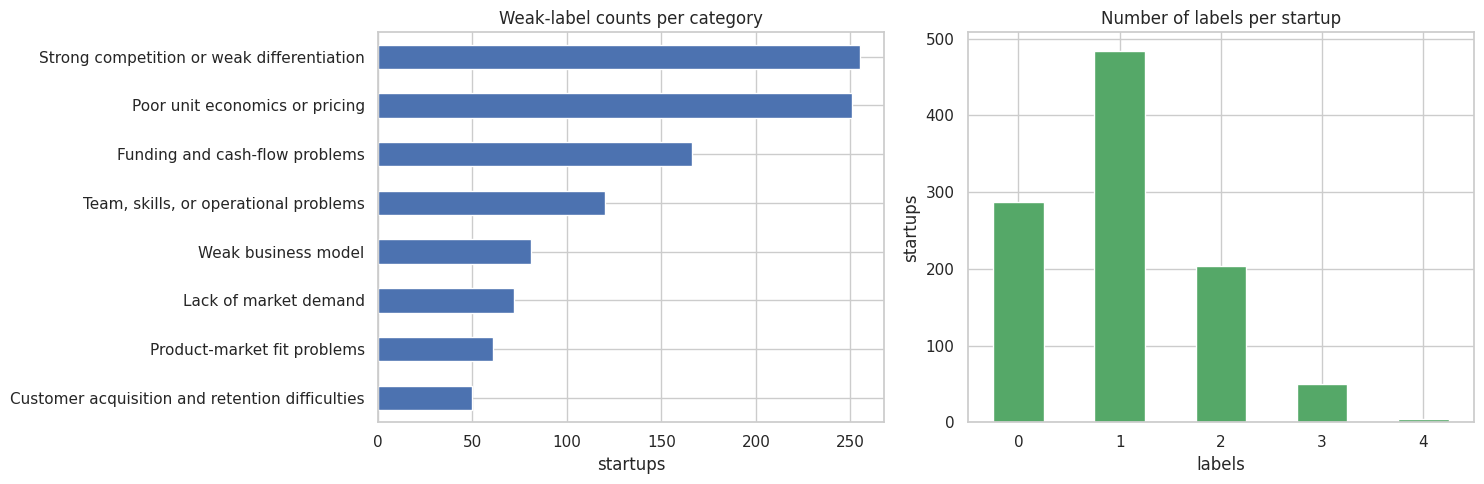

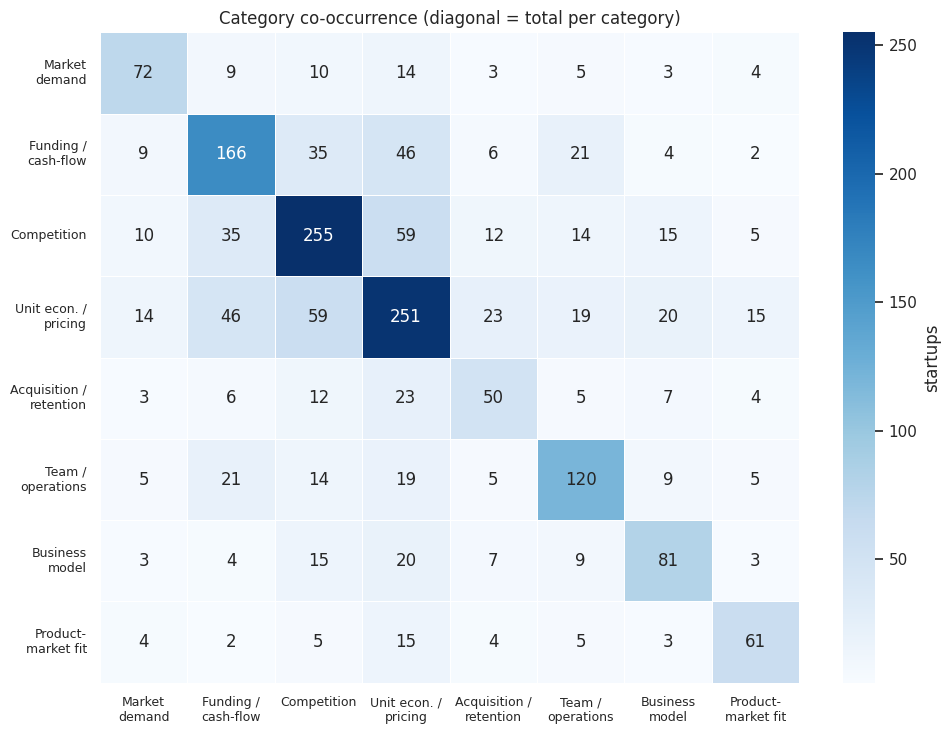

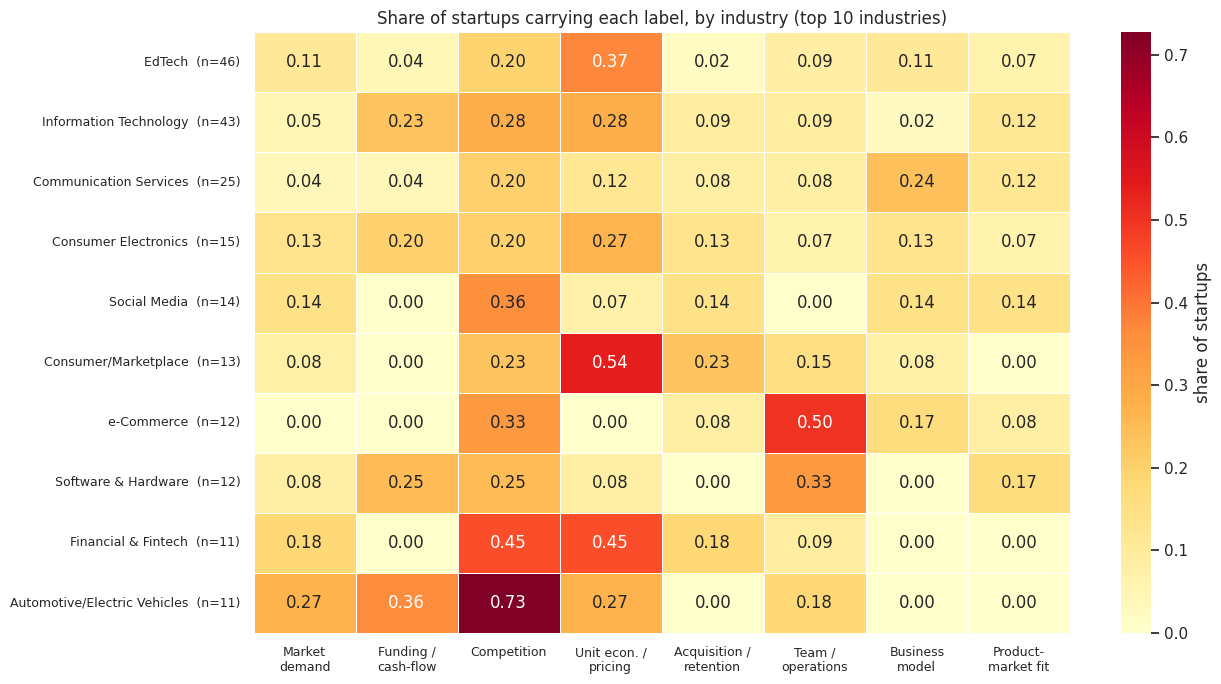

In [8]:
import textwrap
SHORT = {"market_demand": "Market\ndemand", "funding_cashflow": "Funding /\ncash-flow", "competition_differentiation": "Competition",
         "unit_economics_pricing": "Unit econ. /\npricing", "acquisition_retention": "Acquisition /\nretention", "team_operations": "Team /\noperations",
         "weak_business_model": "Business\nmodel", "product_market_fit": "Product-\nmarket fit"}
short_labels = [SHORT[c] for c in CLASSES]

# --- figure A: counts + number of labels per startup
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
Y_all.sum().rename(index=CATEGORY_NAMES).sort_values().plot(kind="barh", ax=ax[0], color="#4C72B0")
ax[0].set_title("Weak-label counts per category"); ax[0].set_xlabel("startups")
df["n_labels"].value_counts().sort_index().plot(kind="bar", ax=ax[1], color="#55A868", rot=0)
ax[1].set_title("Number of labels per startup"); ax[1].set_xlabel("labels"); ax[1].set_ylabel("startups")
plt.tight_layout(); plt.show()

# --- figure B: co-occurrence
co = Y_all.T.dot(Y_all)
plt.figure(figsize=(10, 7.5))
sns.heatmap(co.values, annot=True, fmt="d", cmap="Blues", xticklabels=short_labels, yticklabels=short_labels,
            linewidths=0.5, cbar_kws={"label": "startups"})
plt.title("Category co-occurrence (diagonal = total per category)"); plt.xticks(rotation=0, fontsize=9); plt.yticks(rotation=0, fontsize=9)
plt.tight_layout(); plt.show()

# --- figure C: top industries x category
top_ind = df["industry"].value_counts().head(10).index
m_ind = df["industry"].isin(top_ind)
share = Y_all[m_ind].groupby(df.loc[m_ind, "industry"]).mean().loc[top_ind]
share.index = [textwrap.shorten(i, 32, placeholder="...") + f"  (n={int((df['industry'] == j).sum())})" for i, j in zip(share.index, top_ind)]
plt.figure(figsize=(13, 7))
sns.heatmap(share.values, annot=True, fmt=".2f", cmap="YlOrRd", xticklabels=short_labels, yticklabels=list(share.index),
            linewidths=0.5, cbar_kws={"label": "share of startups"})
plt.title("Share of startups carrying each label, by industry (top 10 industries)")
plt.xticks(rotation=0, fontsize=9); plt.yticks(rotation=0, fontsize=9); plt.ylabel("")
plt.tight_layout(); plt.show()

In [9]:
# What is NOT covered by the 8 categories? (informs whether rules need extending)
unl = df[df.n_labels == 0]
cov = {k: unl["text"].str.contains(p, case=False, regex=True).mean() for k, p in OTHER_THEMES.items()}
cov["none of the above"] = 1 - unl["text"].str.contains("|".join(OTHER_THEMES.values()), case=False, regex=True).mean()
print(f"Unlabeled rows: {len(unl)}"); print(pd.Series(cov).round(3).to_string())

cv = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=4)
Xu = cv.fit_transform(unl["text"])
top = pd.Series(np.asarray(Xu.sum(axis=0)).ravel(), index=cv.get_feature_names_out()).sort_values(ascending=False).head(25)
print("\nMost frequent terms in unlabeled rows:"); print(top.to_string())

Unlabeled rows: 287
regulatory                0.185
macro_rates_covid         0.042
acquired_or_acquihired    0.070
none of the above         0.714

Most frequent terms in unlabeled rows:
market            87
regulatory        68
business          58
capital           41
product           36
model             35
risk              34
platform          29
failed            29
ai                29
funding           28
value             27
hardware          27
tech              27
especially        26
company           24
markets           24
failure           23
significant       22
requires          22
data              21
infrastructure    20
acquired          20
parent            19
acquisition       19


### Rule audit (human review): measure how precise the weak-label rules are
The category labels come from regex rules, so model scores only show agreement with those rules. To find out how often a rule-assigned label is actually right, this step exports **30 rule-labelled examples per category** (shuffled) for a human to check.

**Workflow:** download `weak_label_audit_sample.csv` -> fill `label_correct` (`1` = the category genuinely applies to this startup's failure according to the text, `0` = it does not, blank = skip) -> save as `weak_label_audit_reviewed.csv` -> attach it to the notebook as an input (or upload it into `/kaggle/working/model_d/`) -> re-run. Precision per category (with a 95% interval) then goes into the model card and every prediction. Categories below `MIN_RULE_PRECISION` are flagged as low-quality. Until a reviewed file exists the model card says **"rule precision not measured"**.

In [10]:
AUDIT_PER_CATEGORY = 30
rng_a = np.random.RandomState(RANDOM_STATE)
rows = []
for c in CLASSES:
    pos = np.where(Y_all[c].values == 1)[0]
    for i in rng_a.choice(pos, size=min(AUDIT_PER_CATEGORY, len(pos)), replace=False):
        rows.append(dict(audit_id=f"{c}-{i}", category=c, category_name=CATEGORY_NAMES[c], startup=df.at[i, "name"],
                         matched_keywords=", ".join(df.at[i, "matches"][c]), text=df.at[i, "text"], label_correct=""))
audit = pd.DataFrame(rows).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)   # shuffled: no category anchoring
audit.to_csv(OUT_DIR / "weak_label_audit_sample.csv", index=False)
print("Saved:", OUT_DIR / "weak_label_audit_sample.csv", "|", len(audit), "rows to review")

Saved: /kaggle/working/model_d/weak_label_audit_sample.csv | 240 rows to review


In [11]:
REVIEWED_NAME, MIN_RULE_PRECISION, MIN_REVIEWED = "weak_label_audit_reviewed.csv", 0.70, 10

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d; half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return centre - half, centre + half

cands = [OUT_DIR / REVIEWED_NAME] + (list(INPUT_ROOT.rglob(REVIEWED_NAME)) if INPUT_ROOT.exists() else [])
reviewed_path = next((p for p in cands if p.exists()), None)
RULE_PRECISION, LOW_PRECISION = {}, []
if reviewed_path is None:
    print(f"No reviewed audit file ('{REVIEWED_NAME}') found -> rule precision is NOT MEASURED.\n"
          "Model metrics below therefore mean agreement with unaudited rules. Fill the audit sample and re-run to measure it.")
else:
    rv = pd.read_csv(reviewed_path)
    rv["label_correct"] = pd.to_numeric(rv["label_correct"], errors="coerce")
    rv = rv[rv["label_correct"].isin([0, 1])]
    for c in CLASSES:
        s = rv.loc[rv["category"] == c, "label_correct"]; n = len(s)
        if n >= MIN_REVIEWED:
            k = int(s.sum()); lo, hi = wilson(k, n)
            RULE_PRECISION[c] = dict(precision=round(k / n, 3), n=n, ci95=[round(float(lo), 3), round(float(hi), 3)])
            if k / n < MIN_RULE_PRECISION: LOW_PRECISION.append(c)
    print("Reviewed file:", reviewed_path)
    display(pd.DataFrame(RULE_PRECISION).T)
    not_enough = [c for c in CLASSES if c not in RULE_PRECISION]
    if not_enough: print(f"Fewer than {MIN_REVIEWED} reviewed rows (precision not reported):", not_enough)
    if LOW_PRECISION: print(f"LOW-PRECISION rules (< {MIN_RULE_PRECISION:.0%}) - refine them in section 4 and re-run:", LOW_PRECISION)

No reviewed audit file ('weak_label_audit_reviewed.csv') found -> rule precision is NOT MEASURED.
Model metrics below therefore mean agreement with unaudited rules. Fill the audit sample and re-run to measure it.


## 6. Train / test split (grouped by company)
`GroupShuffleSplit` on the normalised company name keeps duplicate/related entries of one company on the same side.  
Among 40 candidate seeds, the split whose per-category prevalence best matches between train and test is selected (deterministic).

In [12]:
keep = (df.n_labels > 0) if EXCLUDE_UNLABELED else pd.Series(True, index=df.index)
data = df[keep].reset_index(drop=True)
Y = Y_all[keep].reset_index(drop=True).values
print("Modelling rows:", len(data), "| excluded (no category):", (~keep).sum())

def pick_split(seeds=range(40)):
    best = None
    prev = Y.mean(0)
    for s in seeds:
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=s).split(data, groups=data["group"]))
        gap = np.max(np.abs(Y[tr].mean(0) - Y[te].mean(0)) / np.maximum(prev, 1e-9))
        if best is None or gap < best[0]:
            best = (gap, s, tr, te)
    return best

gap, split_seed, tr_idx, te_idx = pick_split()
print(f"Chosen split seed {split_seed} (max relative prevalence gap {gap:.2f})")
print(pd.DataFrame({"train": Y[tr_idx].sum(0), "test": Y[te_idx].sum(0)}, index=CLASSES))
assert set(data.loc[tr_idx, "group"]).isdisjoint(set(data.loc[te_idx, "group"])), "company leakage!"

SUPPORTED = [j for j in range(len(CLASSES)) if Y[tr_idx, j].sum() >= MIN_POSITIVES]
UNSUPPORTED = [CLASSES[j] for j in range(len(CLASSES)) if j not in SUPPORTED]
print("Modelled categories:", len(SUPPORTED), "| not modelled (too few positives):", UNSUPPORTED)

Modelling rows: 741 | excluded (no category): 287
Chosen split seed 31 (max relative prevalence gap 0.21)
                             train  test
market_demand                   58    14
funding_cashflow               132    34
competition_differentiation    202    53
unit_economics_pricing         205    46
acquisition_retention           39    11
team_operations                 92    28
weak_business_model             66    15
product_market_fit              49    12
Modelled categories: 8 | not modelled (too few positives): []


## 7. Feature engineering — sentence embeddings
- Each text is encoded by a **frozen** sentence-transformer into a normalised vector.
- To reduce keyword memorisation, each *training* text also gets a **keyword-masked copy** (same labels).
- The *test* set is evaluated twice: original text, and keyword-masked text (the harder generalisation check).

> The encoder is chosen in this order: (1) a copy attached as a Kaggle input (**no internet needed**), (2) download from Hugging Face (needs **Internet ON** in Kaggle settings), (3) **offline fallback**: a TF-IDF + truncated-SVD (LSA) encoder fitted on the training rows only, which needs no internet and no download. The fallback is slightly weaker semantically; the notebook prints which encoder was used and the choice is saved in the model card. Set `ENCODER_MODE` in the config cell to force a specific behaviour. The encoder is saved with the model so inference works offline.

In [13]:
import socket
from pathlib import Path

# ---------- offline fallback encoder (no Internet, no download, no extra package) ----------
LSA_SRC = r"""
class LSAEncoder:
    # Offline fallback text encoder: TF-IDF -> truncated SVD (LSA) -> L2-normalised vectors.
    # Same .encode() signature as SentenceTransformer, so the rest of the code is encoder-agnostic.
    def __init__(self, tfidf, svd):
        self.tfidf, self.svd = tfidf, svd

    @classmethod
    def fit(cls, texts, dim=256, seed=42):
        from sklearn.feature_extraction.text import TfidfVectorizer
        from sklearn.decomposition import TruncatedSVD
        tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=60000, stop_words="english")
        X = tfidf.fit_transform(texts)
        k = max(2, min(dim, X.shape[1] - 1, X.shape[0] - 1))
        svd = TruncatedSVD(n_components=k, random_state=seed).fit(X)
        return cls(tfidf, svd)

    def encode(self, texts, batch_size=64, normalize_embeddings=True, show_progress_bar=False, convert_to_numpy=True):
        Z = self.svd.transform(self.tfidf.transform(list(texts)))
        n = np.linalg.norm(Z, axis=1, keepdims=True); n[n == 0] = 1.0
        return (Z / n).astype(np.float32)
"""
exec(LSA_SRC)

# ---------- sentence-transformer loading (never crashes the notebook in "auto" mode) ----------
def find_local_encoder():
    """Look for an encoder folder attached as a Kaggle input (a folder that contains modules.json)."""
    if EMBED_MODEL_LOCAL and (Path(EMBED_MODEL_LOCAL) / "modules.json").exists():
        return Path(EMBED_MODEL_LOCAL)
    if INPUT_ROOT.exists():
        for p in INPUT_ROOT.rglob("modules.json"):
            if "minilm" in str(p).lower():
                return p.parent
    return None

def hf_reachable(host="huggingface.co", timeout=5):
    try:
        socket.create_connection((host, 443), timeout=timeout).close(); return True
    except OSError:
        return False

def try_sentence_transformer():
    """Returns ((encoder, source), None) on success or (None, reason) on failure."""
    try:
        from sentence_transformers import SentenceTransformer
    except Exception as e:
        return None, f"the sentence-transformers package could not be imported ({type(e).__name__})"
    local = find_local_encoder()
    if local is not None:
        source = str(local)
    elif hf_reachable():
        source = EMBED_MODEL
    else:
        return None, "Internet is OFF and no local copy of the encoder was found"
    try:
        return (SentenceTransformer(source), source), None
    except Exception as e:
        return None, f"could not load '{source}' ({type(e).__name__}: {str(e)[:120]})"

assert ENCODER_MODE in ("auto", "sentence_transformer", "lsa"), "ENCODER_MODE must be 'auto', 'sentence_transformer' or 'lsa'"
data["text_masked"] = data["text"].map(mask_keywords)

ENCODER_KIND, ENCODER_SOURCE, ENCODER_FALLBACK_REASON = None, None, None
if ENCODER_MODE in ("auto", "sentence_transformer"):
    res, err = try_sentence_transformer()
    if res is not None:
        encoder, ENCODER_SOURCE = res; ENCODER_KIND = "sentence_transformer"
    elif ENCODER_MODE == "sentence_transformer":
        raise RuntimeError(f"Cannot load the sentence encoder: {err}.\n"
            "Fix with ONE of these, then re-run this cell:\n"
            "  A) Kaggle right panel -> Session options / Settings -> turn Internet ON (account must be phone-verified), or\n"
            "  B) Notebook -> Add Input -> Models -> search 'all-MiniLM-L6-v2' (sentence-transformers) -> Add, or\n"
            "     attach a dataset whose folder contains modules.json (set EMBED_MODEL_LOCAL if it is not auto-detected), or\n"
            "  C) set ENCODER_MODE = 'auto' to use the offline fallback encoder.")
    else:
        ENCODER_FALLBACK_REASON = err
        print(f"[!] Sentence encoder unavailable: {err}.\n"
              "    -> Using the OFFLINE fallback encoder (TF-IDF + truncated SVD, fitted on TRAIN rows only).\n"
              "    -> For better semantic embeddings: turn Internet ON or attach all-MiniLM-L6-v2 as a Kaggle input, then re-run.\n")

if ENCODER_KIND is None:
    # fitted on the TRAIN split only (original + keyword-masked copies) so nothing from the test rows leaks in
    fit_texts = list(data.loc[tr_idx, "text"]) + list(data.loc[tr_idx, "text_masked"])
    encoder = LSAEncoder.fit(fit_texts, dim=LSA_DIM, seed=RANDOM_STATE)
    ENCODER_KIND, ENCODER_SOURCE = "lsa", f"LSA(TF-IDF 1-2gram + TruncatedSVD, dim={encoder.svd.n_components})"

print("Encoder kind  :", ENCODER_KIND)
print("Encoder source:", ENCODER_SOURCE)

def embed(texts, batch_size=64):
    return np.asarray(encoder.encode(list(texts), batch_size=batch_size, normalize_embeddings=True,
                                     show_progress_bar=False, convert_to_numpy=True), dtype=np.float32)

E_orig = embed(data["text"])
E_mask = embed(data["text_masked"])
print("Embedding matrix:", E_orig.shape)
print("\nMasking example:\n  ORIGINAL:", data["text"].iloc[0][:200], "\n  MASKED  :", data["text_masked"].iloc[0][:200])


[!] Sentence encoder unavailable: Internet is OFF and no local copy of the encoder was found.
    -> Using the OFFLINE fallback encoder (TF-IDF + truncated SVD, fitted on TRAIN rows only).
    -> For better semantic embeddings: turn Internet ON or attach all-MiniLM-L6-v2 as a Kaggle input, then re-run.

Encoder kind  : lsa
Encoder source: LSA(TF-IDF 1-2gram + TruncatedSVD, dim=256)
Embedding matrix: (741, 256)

Masking example:
  ORIGINAL: Unsustainable Unit Economics. Sydney's quick-commerce darling raised AUD$75M+ then collapsed inside 18 months when capital tightened. Australian density couldn't support 10-minute grocery economics. 
  MASKED  : . Sydney's quick-commerce darling raised AUD$75M+ then collapsed inside 18 months when . Australian density couldn't support 10-minute grocery economics.


In [14]:
# training matrices (original + optional masked copies); groups are shared so copies stay in the same CV fold
Xtr_o, Ytr = E_orig[tr_idx], Y[tr_idx]
Xte_o, Xte_m, Yte = E_orig[te_idx], E_mask[te_idx], Y[te_idx]
gtr_codes = pd.factorize(data.loc[tr_idx, "group"])[0]

if USE_MASK_AUG:
    X_aug = np.vstack([Xtr_o, E_mask[tr_idx]]); Y_aug = np.vstack([Ytr, Ytr]); g_aug = np.concatenate([gtr_codes, gtr_codes])
else:
    X_aug, Y_aug, g_aug = Xtr_o, Ytr, gtr_codes
n_orig = len(Xtr_o)
print("Training rows (with augmentation):", X_aug.shape)

Training rows (with augmentation): (1186, 256)


## 8. Model training
For each category: Logistic Regression (`class_weight="balanced"`) on embeddings.

1. **C selection** — grouped 5-fold CV, choose the C with the best macro average-precision on out-of-fold (OOF) predictions of the *original* rows.
2. **Calibration** — Platt scaling (sigmoid) fitted on OOF scores → calibrated probabilities.
3. **Thresholds** — per-category threshold maximising F1 on calibrated OOF probabilities.
4. Final model is fitted on the full training split; the **test set is never used** for steps 1–3.

In [15]:
def fit_lr(X, y, C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE).fit(X, y)

def oof_scores(C):
    oof = np.full(Y_aug.shape, np.nan, dtype=float)
    for tr, va in GroupKFold(n_splits=CV_FOLDS).split(X_aug, groups=g_aug):
        for j in SUPPORTED:
            y = Y_aug[tr, j]
            if y.sum() == 0 or y.sum() == len(y):
                continue
            oof[va, j] = fit_lr(X_aug[tr], y, C).decision_function(X_aug[va])
    return oof

def macro_ap(oof):
    aps = []
    for j in SUPPORTED:
        ok = ~np.isnan(oof[:n_orig, j])
        aps.append(average_precision_score(Ytr[ok, j], oof[:n_orig][ok, j]))
    return float(np.mean(aps))

cv_results = {}
for C in C_GRID:
    o = oof_scores(C); cv_results[C] = (macro_ap(o), o)
    print(f"C={C:<5} OOF macro-AP = {cv_results[C][0]:.4f}")
BEST_C = max(cv_results, key=lambda c: cv_results[c][0])
oof = cv_results[BEST_C][1]
print("Selected C =", BEST_C)

C=0.3   OOF macro-AP = 0.7502
C=1.0   OOF macro-AP = 0.7384
C=3.0   OOF macro-AP = 0.7200
C=10.0  OOF macro-AP = 0.6993
Selected C = 0.3


In [16]:
# Platt calibrators + per-class thresholds from OOF predictions (original rows only)
calibrators, thresholds = {}, {}
grid = np.linspace(0.05, 0.95, 91)
for j in SUPPORTED:
    c = CLASSES[j]
    ok = ~np.isnan(oof[:n_orig, j])
    s, y = oof[:n_orig][ok, j], Ytr[ok, j]
    calibrators[c] = LogisticRegression(C=1e6, max_iter=1000).fit(s[:, None], y)
    p = calibrators[c].predict_proba(s[:, None])[:, 1]
    f1s = [f1_score(y, p >= t, zero_division=0) for t in grid]
    thresholds[c] = float(grid[int(np.argmax(f1s))])
print(pd.Series(thresholds).round(2).rename("threshold").to_string())

# final model on the full training split
models = {CLASSES[j]: fit_lr(X_aug, Y_aug[:, j], BEST_C) for j in SUPPORTED}

def predict_probs(X, models_=None):
    mdl = models_ or models
    P = np.full((len(X), len(CLASSES)), np.nan)
    for j, c in enumerate(CLASSES):
        if c in mdl:
            P[:, j] = calibrators[c].predict_proba(mdl[c].decision_function(X)[:, None])[:, 1]
    return P

def predict_labels(P):
    out = np.zeros(P.shape, dtype=int)
    for j, c in enumerate(CLASSES):
        if c in thresholds:
            out[:, j] = (P[:, j] >= thresholds[c]).astype(int)
    return out

market_demand                  0.36
funding_cashflow               0.35
competition_differentiation    0.44
unit_economics_pricing         0.55
acquisition_retention          0.22
team_operations                0.36
weak_business_model            0.28
product_market_fit             0.48


## 9. Evaluation on the held-out test set
Reported separately for **original text** and **keyword-masked text**. Because labels are rule-derived, treat these numbers as *agreement with the weak labels*, and the masked-text numbers as the more honest indicator of generalisation.

In [17]:
def evaluate(Yt, P, Yp, label):
    rows = []
    for j in SUPPORTED:
        yt, p, yp = Yt[:, j], P[:, j], Yp[:, j]
        both = len(np.unique(yt)) == 2
        rows.append(dict(category=CLASSES[j], support=int(yt.sum()), prevalence=yt.mean(),
                         precision=precision_score(yt, yp, zero_division=0), recall=recall_score(yt, yp, zero_division=0),
                         f1=f1_score(yt, yp, zero_division=0),
                         avg_precision=average_precision_score(yt, p) if both else np.nan,
                         roc_auc=roc_auc_score(yt, p) if both else np.nan,
                         brier=brier_score_loss(yt, p)))
    tab = pd.DataFrame(rows).set_index("category")
    S = SUPPORTED
    agg = dict(split=label, micro_f1=f1_score(Yt[:, S], Yp[:, S], average="micro", zero_division=0),
               macro_f1=f1_score(Yt[:, S], Yp[:, S], average="macro", zero_division=0),
               samples_f1=f1_score(Yt[:, S], Yp[:, S], average="samples", zero_division=0),
               macro_avg_precision=tab["avg_precision"].mean(), macro_roc_auc=tab["roc_auc"].mean(),
               hamming_loss=hamming_loss(Yt[:, S], Yp[:, S]), subset_accuracy=accuracy_score(Yt[:, S], Yp[:, S]))
    return tab, agg

P_o = predict_probs(Xte_o); Yp_o = predict_labels(P_o)
P_m = predict_probs(Xte_m); Yp_m = predict_labels(P_m)
tab_o, agg_o = evaluate(Yte, P_o, Yp_o, "test_original")
tab_m, agg_m = evaluate(Yte, P_m, Yp_m, "test_keyword_masked")

print("=== Per-category, ORIGINAL test text ==="); display(tab_o.round(3))
print("=== Per-category, KEYWORD-MASKED test text ==="); display(tab_m.round(3))
summary = pd.DataFrame([agg_o, agg_m]).set_index("split"); print("=== Aggregate ==="); display(summary.round(3))

=== Per-category, ORIGINAL test text ===


,support,prevalence,precision,recall,f1,avg_precision,roc_auc,brier
category,,,,,,,,
market_demand,14,0.095,0.353,0.429,0.387,0.490,0.876,0.086
funding_cashflow,34,0.230,0.592,0.853,0.699,0.874,0.937,0.101
competition_differentiation,53,0.358,0.797,0.887,0.839,0.930,0.953,0.090
unit_economics_pricing,46,0.311,0.824,0.913,0.866,0.935,0.949,0.085
acquisition_retention,11,0.074,0.250,0.636,0.359,0.682,0.823,0.070
team_operations,28,0.189,0.786,0.786,0.786,0.820,0.946,0.066
weak_business_model,15,0.101,0.222,0.400,0.286,0.310,0.739,0.120
product_market_fit,12,0.081,0.500,0.500,0.500,0.566,0.847,0.070


=== Per-category, KEYWORD-MASKED test text ===


,support,prevalence,precision,recall,f1,avg_precision,roc_auc,brier
category,,,,,,,,
market_demand,14,0.095,0.261,0.429,0.324,0.296,0.708,0.118
funding_cashflow,34,0.230,0.440,0.647,0.524,0.508,0.738,0.191
competition_differentiation,53,0.358,0.641,0.774,0.701,0.814,0.862,0.163
unit_economics_pricing,46,0.311,0.714,0.543,0.617,0.643,0.811,0.178
acquisition_retention,11,0.074,0.217,0.455,0.294,0.286,0.657,0.101
team_operations,28,0.189,0.516,0.571,0.542,0.531,0.794,0.141
weak_business_model,15,0.101,0.081,0.200,0.115,0.140,0.454,0.180
product_market_fit,12,0.081,0.000,0.000,0.000,0.128,0.665,0.120


=== Aggregate ===


,micro_f1,macro_f1,samples_f1,macro_avg_precision,macro_roc_auc,hamming_loss,subset_accuracy
split,,,,,,,
test_original,0.682,0.59,0.685,0.701,0.884,0.130,0.365
test_keyword_masked,0.484,0.39,0.476,0.418,0.711,0.213,0.176


In [18]:
# baseline: TF-IDF + OvR logistic regression (same split, same augmentation)
txt_tr = list(data.loc[tr_idx, "text"]) + (list(data.loc[tr_idx, "text_masked"]) if USE_MASK_AUG else [])
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xt_tr = tfidf.fit_transform(txt_tr)
base = OneVsRestClassifier(LogisticRegression(C=3, class_weight="balanced", max_iter=3000)).fit(Xt_tr[:, :], Y_aug[:, SUPPORTED])
def base_scores(texts): return base.predict_proba(tfidf.transform(texts))
rows = []
for name, txts in [("original", data.loc[te_idx, "text"]), ("masked", data.loc[te_idx, "text_masked"])]:
    pb = base_scores(txts)
    ap_b = np.nanmean([average_precision_score(Yte[:, j], pb[:, k]) for k, j in enumerate(SUPPORTED)])
    rows.append(dict(test_text=name, baseline_tfidf_macro_AP=ap_b,
                     embedding_model_macro_AP=(tab_o if name == "original" else tab_m)["avg_precision"].mean()))
print("Embedding model vs TF-IDF baseline (threshold-free comparison):"); display(pd.DataFrame(rows).set_index("test_text").round(3))

Embedding model vs TF-IDF baseline (threshold-free comparison):


,baseline_tfidf_macro_AP,embedding_model_macro_AP
test_text,,
original,0.701,0.701
masked,0.429,0.418


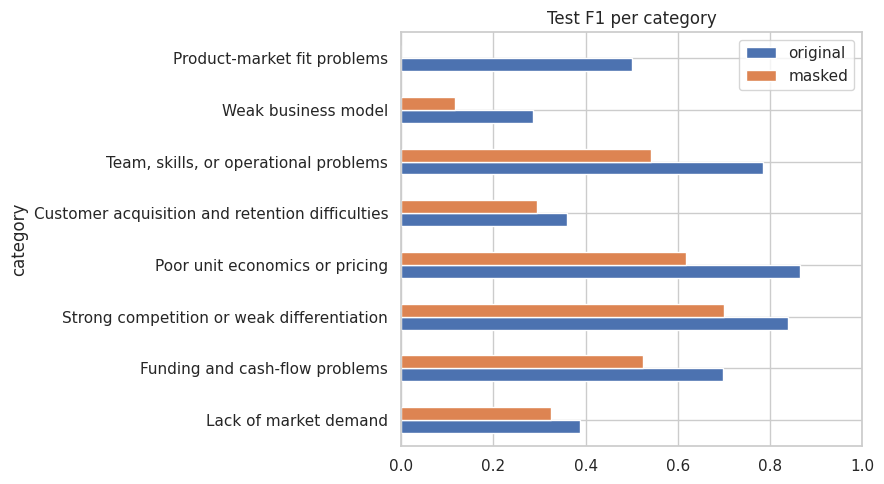

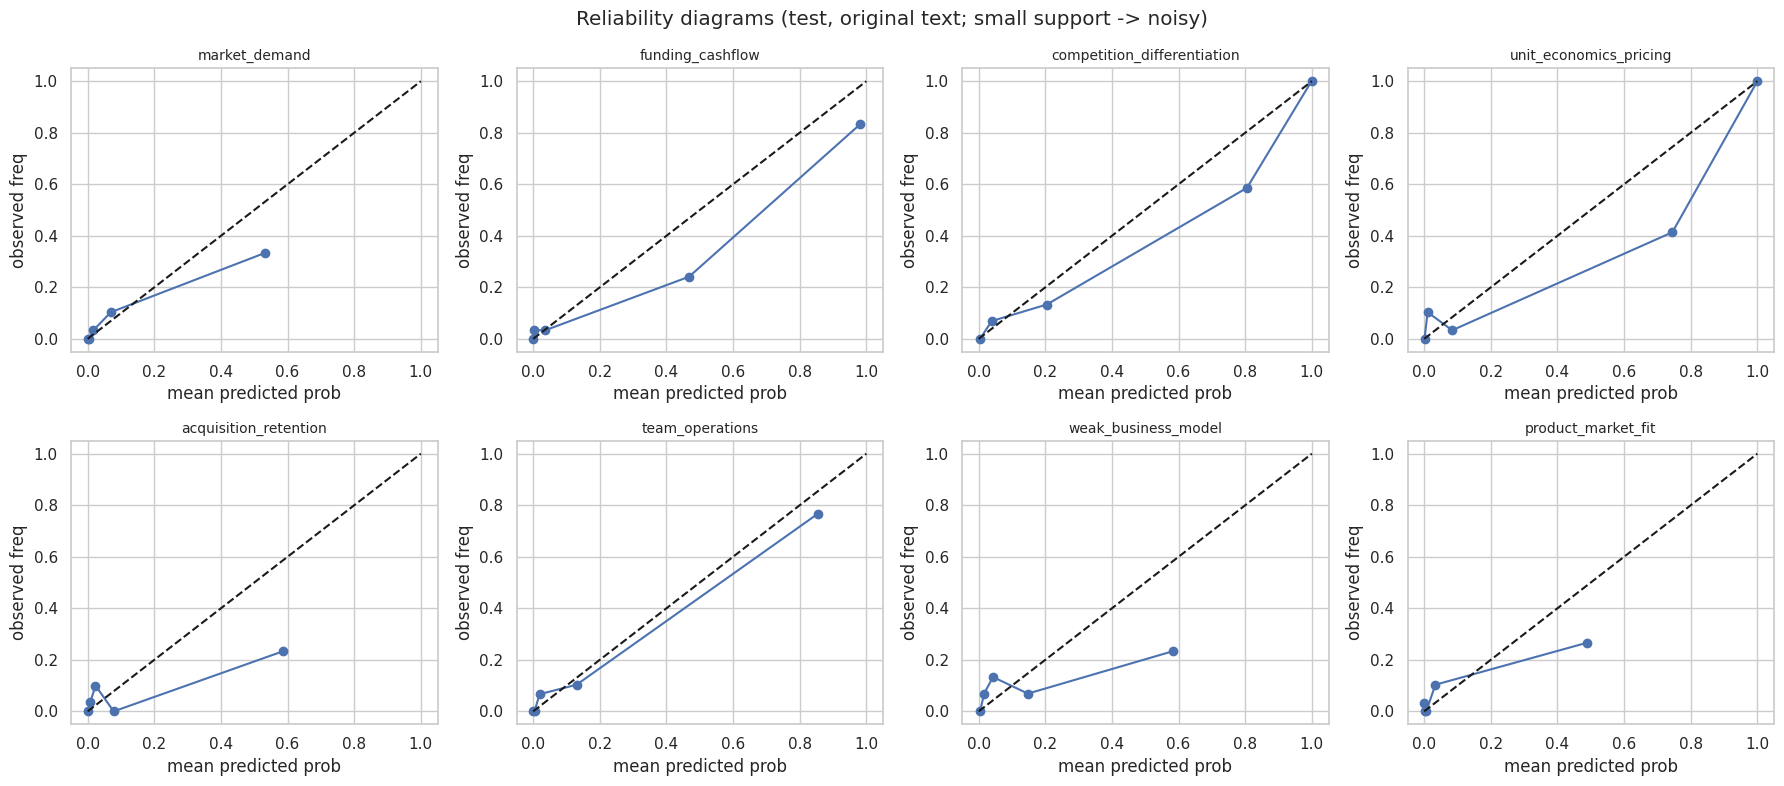

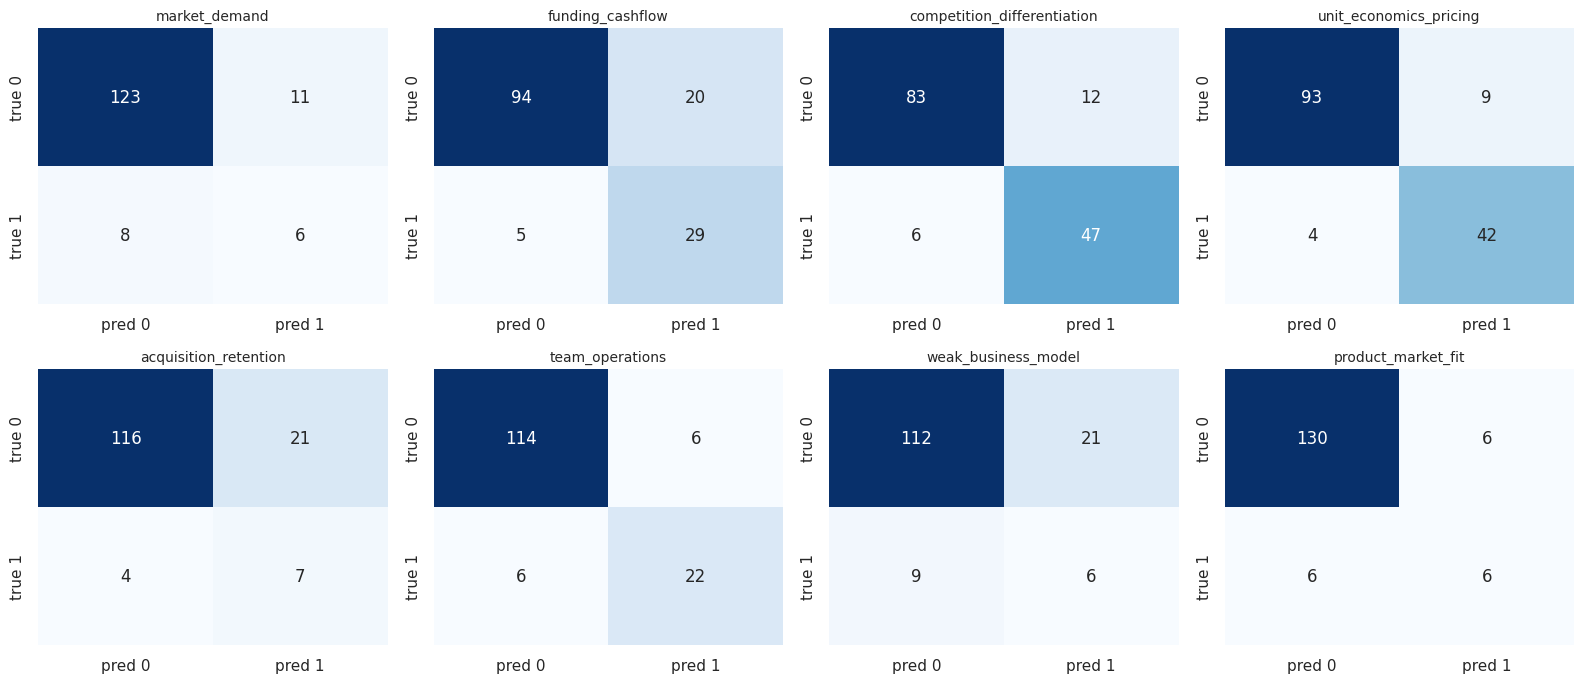

In [19]:
# per-class F1: original vs masked
cmp = pd.DataFrame({"original": tab_o["f1"], "masked": tab_m["f1"]}).rename(index=CATEGORY_NAMES)
cmp.plot(kind="barh", figsize=(9, 5), color=["#4C72B0", "#DD8452"]); plt.title("Test F1 per category"); plt.xlim(0, 1)
plt.tight_layout(); plt.show()

# reliability curves (calibration) on original test text
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, j in zip(axes, SUPPORTED):
    yt, p = Yte[:, j], P_o[:, j]
    if len(np.unique(yt)) == 2:
        fr, mp = calibration_curve(yt, p, n_bins=5, strategy="quantile")
        ax.plot(mp, fr, "o-", label="model")
    ax.plot([0, 1], [0, 1], "k--", label="perfect"); ax.set_title(CLASSES[j], fontsize=10)
    ax.set_xlabel("mean predicted prob"); ax.set_ylabel("observed freq")
plt.suptitle("Reliability diagrams (test, original text; small support -> noisy)"); plt.tight_layout(); plt.show()

# per-class confusion matrices
mcm = multilabel_confusion_matrix(Yte[:, SUPPORTED], Yp_o[:, SUPPORTED])
fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
for ax, m, j in zip(axes, mcm, SUPPORTED):
    sns.heatmap(m, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
    ax.set_title(CLASSES[j], fontsize=10)
plt.tight_layout(); plt.show()

In [20]:
# error analysis: disagreements with the weak labels on the masked test text
errs = []
for i in range(len(te_idx)):
    t = [CLASSES[j] for j in SUPPORTED if Yte[i, j]]; p = [CLASSES[j] for j in SUPPORTED if Yp_m[i, j]]
    if set(t) != set(p): errs.append((data.loc[te_idx[i], "text_masked"][:160], t, p))
print(f"{len(errs)} of {len(te_idx)} test rows have a label-set mismatch on masked text. Sample:")
for e in errs[:8]: print("\n-", e[0], "\n   weak label:", e[1], "\n   predicted :", e[2])

122 of 148 test rows have a label-set mismatch on masked text. Sample:

- Rates & BNPL Reckoning. Australia's solar-financing BNPL hit the same wall as global BNPL: rising rates, rising defaults, at peak valuation. 
   weak label: ['unit_economics_pricing', 'weak_business_model'] 
   predicted : ['funding_cashflow', 'unit_economics_pricing']

- & Equity Collapse. ASX-listed Plenti's stock fell over 80% as Australian P2P lending margins evaporated under the rate cycle. 
   weak label: ['unit_economics_pricing'] 
   predicted : ['funding_cashflow', 'unit_economics_pricing']

- RPA as 'AI', ROI to hospitals. Selling AI to hospitals requires proven ROI per workflow, not a $4B narrative. Olive's automation broke on messy edge cases and c 
   weak label: ['product_market_fit'] 
   predicted : []

- SEC probe, , and more capital. Post-SPAC EV plays with unresolved SEC issues can't raise follow-on capital. ELMS in 18 months. 
   weak label: ['funding_cashflow', 'team_operations'] 
   predicted

## 9b. Out-of-distribution guard
Training text is post-mortem writing about failed startups; real inputs are forward-looking idea descriptions. For every held-out text the notebook measures the cosine similarity to its **nearest training case**. The 5th percentile of that distribution becomes the warning threshold: a new input below it is flagged as unlike the data the model learned from.

Nearest-train-case similarity on held-out texts: {'p05': 0.3605, 'p50': 0.5025, 'p95': 0.7006} | warning threshold = 0.3605


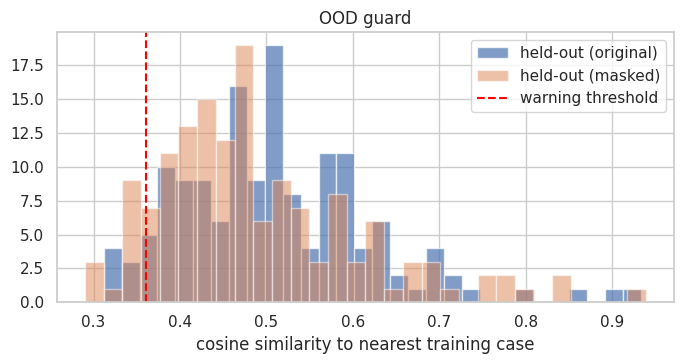

In [21]:
sim_te   = (Xte_o @ Xtr_o.T).max(axis=1)      # nearest TRAIN case for each held-out text (out-of-sample)
sim_te_m = (Xte_m @ Xtr_o.T).max(axis=1)
OOD_SIM_THRESHOLD = float(np.percentile(sim_te, 5))
OOD_REF = {"p05": round(float(np.percentile(sim_te, 5)), 4), "p50": round(float(np.percentile(sim_te, 50)), 4),
           "p95": round(float(np.percentile(sim_te, 95)), 4)}
print("Nearest-train-case similarity on held-out texts:", OOD_REF, "| warning threshold =", round(OOD_SIM_THRESHOLD, 4))
plt.figure(figsize=(7, 3.8))
plt.hist(sim_te, bins=30, alpha=.7, label="held-out (original)"); plt.hist(sim_te_m, bins=30, alpha=.5, label="held-out (masked)")
plt.axvline(OOD_SIM_THRESHOLD, color="red", ls="--", label="warning threshold")
plt.xlabel("cosine similarity to nearest training case"); plt.legend(); plt.title("OOD guard"); plt.tight_layout(); plt.show()

## 10. Final model
The evaluated model (trained on the train split) is re-fitted on **all** modelled rows with the same C, calibrators and thresholds, and saved with the encoder, rules, similar-case index and a model card.

In [22]:
X_full_aug = np.vstack([E_orig, E_mask]) if USE_MASK_AUG else E_orig
Y_full_aug = np.vstack([Y, Y]) if USE_MASK_AUG else Y
final_models = {CLASSES[j]: fit_lr(X_full_aug, Y_full_aug[:, j], BEST_C) for j in SUPPORTED}

# sanity: calibrated probabilities from the final model on the test rows (in-sample now -> only a smoke test)
_ = predict_probs(Xte_o, final_models); print("Final models fitted:", list(final_models))

Final models fitted: ['market_demand', 'funding_cashflow', 'competition_differentiation', 'unit_economics_pricing', 'acquisition_retention', 'team_operations', 'weak_business_model', 'product_market_fit']


In [23]:
# ---- save artifacts ----
def _f(x): return None if pd.isna(x) else round(float(x), 4)
LABEL_QUALITY = {c: (f"rule precision {RULE_PRECISION[c]['precision']:.2f} (n={RULE_PRECISION[c]['n']}, human-reviewed)"
                     if c in RULE_PRECISION else "rule precision not measured (no human audit supplied)") for c in CLASSES}
card = dict(
    meaning=("Each probability is the calibrated likelihood that the text resembles historical failure narratives that carry this category label "
             "(labels come from keyword rules). It is NOT the probability that this startup will fail or will suffer this problem; "
             "categories are predicted risk themes, not confirmed causes."),
    validation_status=dict(
        classifier="validated on a company-grouped held-out split, but only against rule-derived weak labels (agreement with the rules, not ground truth)",
        rules=("human-audited, see label_quality per category" if RULE_PRECISION else "NOT audited: rule precision is unknown"),
        probabilities="Platt-calibrated on out-of-fold predictions; small categories give noisy calibration"),
    test_metrics_original={k: _f(v) for k, v in agg_o.items() if k != "split"},
    test_metrics_keyword_masked={k: _f(v) for k, v in agg_m.items() if k != "split"},
    label_quality=LABEL_QUALITY, low_precision_categories=LOW_PRECISION,
    ood=dict(sim_threshold=OOD_SIM_THRESHOLD, reference=OOD_REF), encoder_kind=ENCODER_KIND)

joblib.dump(dict(classes=CLASSES, category_names=CATEGORY_NAMES, supported=[CLASSES[j] for j in SUPPORTED],
                 models=final_models, calibrators=calibrators, thresholds=thresholds,
                 embed_model=EMBED_MODEL if ENCODER_KIND == "sentence_transformer" else None,
                 encoder_kind=ENCODER_KIND, encoder_source=ENCODER_SOURCE,
                 lsa=(dict(tfidf=encoder.tfidf, svd=encoder.svd) if ENCODER_KIND == "lsa" else None),
                 best_C=BEST_C, card=card), OUT_DIR / "model_d_classifier.joblib")

(OUT_DIR / "label_config.json").write_text(json.dumps(dict(category_names=CATEGORY_NAMES, rules=RULES), indent=2))
if ENCODER_KIND == "sentence_transformer":
    encoder.save(str(OUT_DIR / "sentence_encoder"))      # the LSA fallback is stored inside the joblib file instead

cases = data[["name", "industry", "country", "failure_year", "failure_reason", "lesson"]].copy()
for j, c in enumerate(CLASSES): cases[c] = Y[:, j]
cases.to_csv(OUT_DIR / "cases.csv", index=False)
np.save(OUT_DIR / "case_embeddings.npy", E_orig)

meta = dict(
    model="Model D - Failure Category Classifier (multilabel)",
    created_utc=datetime.utcnow().isoformat(timespec="seconds"),
    provenance=dict(dataset_file=DATA_PATH.name, source_url_column_domain=df_raw["url"].str.extract(r"https?://([^/]+)")[0].mode().iat[0],
                    rows_raw=int(len(df_raw)), rows_after_cleaning=int(len(df)), rows_modelled=int(len(data)),
                    training_text="failure_reason + lesson", label_method="regex weak labels, rule set v2 with qualified patterns (see label_config.json)",
                    all_rows_are_failed_startups=True),
    split=dict(method="GroupShuffleSplit by company name", seed=int(split_seed), test_size=TEST_SIZE,
               train_rows=int(len(tr_idx)), test_rows=int(len(te_idx))),
    modelled_categories=[CLASSES[j] for j in SUPPORTED], not_modelled_categories=UNSUPPORTED,
    hyperparameters=dict(encoder_kind=ENCODER_KIND, encoder_source=ENCODER_SOURCE, encoder_fallback_reason=ENCODER_FALLBACK_REASON,
                     embed_model=EMBED_MODEL if ENCODER_KIND == "sentence_transformer" else None, C=BEST_C, class_weight="balanced", mask_augmentation=USE_MASK_AUG, cv_folds=CV_FOLDS),
    rule_audit=dict(reviewed_file=(reviewed_path.name if reviewed_path else None), precision_by_category=RULE_PRECISION,
                    low_precision_categories=LOW_PRECISION, min_rule_precision=MIN_RULE_PRECISION),
    ood_guard=dict(method="cosine similarity to nearest training case, 5th percentile of held-out texts", **card["ood"]),
    thresholds={k: round(v, 3) for k, v in thresholds.items()},
    test_metrics_original={k: _f(v) for k, v in agg_o.items() if k != "split"},
    test_metrics_keyword_masked={k: _f(v) for k, v in agg_m.items() if k != "split"},
    per_category_test_f1_original={k: _f(v) for k, v in tab_o["f1"].items()},
    per_category_test_f1_masked={k: _f(v) for k, v in tab_m["f1"].items()},
    note_on_metrics="Test metrics come from the model fitted on the train split only; the saved model is re-fitted on all rows.",
    limitations=[
        "Labels are rule-derived weak labels, not human annotations; metrics measure agreement with the rules.",
        "Training text is post-mortem narratives of failed startups; user input is forward-looking, so a domain shift exists.",
        "All training rows are failures: the model cannot estimate whether a startup will fail.",
        "Outputs are predicted risk themes, not confirmed causes.",
        "Regulatory, macro and acquisition-driven failures are outside the 8-category taxonomy.",
        "Probabilities are calibrated against weak labels on out-of-fold data; small categories give noisy calibration."]
    + ([] if RULE_PRECISION else ["The weak-label rules have NOT been audited by a human: rule precision is unknown, so test metrics only show agreement with the rules."])
    + ([f"Low audited rule precision for: {', '.join(LOW_PRECISION)}."] if LOW_PRECISION else [])
    + (["The offline fallback encoder (TF-IDF + SVD) was used because the sentence encoder could not be loaded; it captures wording rather than meaning, "
        "so re-run with Internet ON or the MiniLM model attached for better generalisation."] if ENCODER_KIND == "lsa" else []),
    library_versions=dict(sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__))
(OUT_DIR / "model_d_metadata.json").write_text(json.dumps(meta, indent=2))
print("Saved files:")
for p in sorted(OUT_DIR.iterdir()):
    print(" ", p.name)

Saved files:
  case_embeddings.npy
  cases.csv
  label_config.json
  model_d_classifier.joblib
  model_d_metadata.json
  weak_label_audit_sample.csv


## 11. Inference module
`model_d_inference.py` is written next to the model so the backend can import it. For each category it returns the probability, the predicted flag, the **most relevant sentence** of the user's text, rule keyword matches, and **similar historical failures** (nearest neighbours that carry the same label).

In [24]:
INFERENCE_SRC = r'''
"""Model D inference: multilabel failure-risk categories for a startup description."""
import json, re
from pathlib import Path
import numpy as np, pandas as pd, joblib

#__LSA_ENCODER__


class FailureCategoryClassifier:
    NOTE = ("Categories are PREDICTED risk themes learned from historical failure narratives (weak, rule-derived labels). "
            "They are not confirmed causes and not a prediction that the startup will fail.")

    def __init__(self, artifact_dir):
        d = Path(artifact_dir)
        self.art = joblib.load(d / "model_d_classifier.joblib")
        cfg = json.loads((d / "label_config.json").read_text())
        self.rules = {k: re.compile("|".join(f"(?:{p})" for p in v), re.I) for k, v in cfg["rules"].items()}
        if self.art.get("encoder_kind", "sentence_transformer") == "lsa":
            self.encoder = LSAEncoder(self.art["lsa"]["tfidf"], self.art["lsa"]["svd"])     # offline fallback encoder
        else:
            from sentence_transformers import SentenceTransformer
            enc = d / "sentence_encoder"
            self.encoder = SentenceTransformer(str(enc) if enc.exists() else self.art["embed_model"])
        self.cases = pd.read_csv(d / "cases.csv")
        self.case_emb = np.load(d / "case_embeddings.npy")

    def _embed(self, texts):
        return np.asarray(self.encoder.encode(list(texts), normalize_embeddings=True, show_progress_bar=False,
                                              convert_to_numpy=True), dtype=np.float32)

    def _probs(self, E):
        a = self.art
        P = np.full((len(E), len(a["classes"])), np.nan)
        for j, c in enumerate(a["classes"]):
            if c in a["models"]:
                s = a["models"][c].decision_function(E)
                P[:, j] = a["calibrators"][c].predict_proba(s[:, None])[:, 1]
        return P

    def predict(self, text, top_k_cases=3):
        text = re.sub(r"\s+", " ", str(text or "")).strip()
        warnings = []
        if len(text.split()) < 20:
            warnings.append("Input is very short (<20 words); category estimates are unreliable.")
        if not text:
            return dict(model="D", categories=[], warnings=warnings + ["Empty input."], note=self.NOTE, meaning=self.art.get("card", {}).get("meaning"))

        a = self.art
        E = self._embed([text]); p = self._probs(E)[0]
        sents = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text) if len(s.split()) >= 4]
        if len(sents) > 1:
            Ps = self._probs(self._embed(sents))
        else:
            sents, Ps = [text], p[None, :]
        sims = self.case_emb @ E[0]
        card = a.get("card", {})
        ood_cfg = card.get("ood", {})
        max_sim = float(sims.max())
        ood_flag = bool(ood_cfg) and max_sim < ood_cfg["sim_threshold"]
        if ood_flag:
            warnings.append(f"The text is unlike the historical failure narratives the model learned from (nearest-case similarity {max_sim:.2f} "
                            f"is below the typical lower bound {ood_cfg['sim_threshold']:.2f}). Treat the categories as weak signals.")

        out = []
        for j, c in enumerate(a["classes"]):
            if c not in a["models"]:
                out.append(dict(category=c, label=a["category_names"][c], supported=False,
                                reason="Not modelled: too few training examples."))
                continue
            kw = sorted({m.group(0).lower() for m in self.rules[c].finditer(text)})
            mask = (self.cases[c] == 1).values
            idx = np.where(mask)[0]
            top = idx[np.argsort(-sims[idx])[:top_k_cases]]
            out.append(dict(
                category=c, label=a["category_names"][c], supported=True,
                probability=round(float(p[j]), 4), threshold=round(a["thresholds"][c], 3),
                predicted=bool(p[j] >= a["thresholds"][c]),
                label_quality=card.get("label_quality", {}).get(c, "unknown"),
                evidence_sentence=sents[int(np.argmax(Ps[:, j]))],
                keyword_matches=kw,
                similar_historical_failures=[dict(name=self.cases.name[i], industry=self.cases.industry[i],
                                                  failure_reason=self.cases.failure_reason[i],
                                                  similarity=round(float(sims[i]), 3)) for i in top]))
        out.sort(key=lambda r: -r.get("probability", -1))
        predicted = [r["category"] for r in out if r.get("predicted")]
        if not predicted:
            warnings.append("No category reached its decision threshold. This does not mean the startup has no risks, only that the text does not "
                            "resemble the failure patterns this model knows.")
        for c in predicted:
            if c in card.get("low_precision_categories", []):
                warnings.append(f"'{a['category_names'][c]}': the labelling rule behind this category had low audited precision; treat it as unreliable.")
        return dict(model="D", categories=out, predicted_categories=predicted, warnings=warnings, note=self.NOTE,
                    meaning=card.get("meaning"), validation_status=card.get("validation_status"),
                    test_metrics=dict(original_text=card.get("test_metrics_original"), keyword_masked_text=card.get("test_metrics_keyword_masked")),
                    ood=dict(nearest_case_similarity=round(max_sim, 3), threshold=ood_cfg.get("sim_threshold"), flagged=ood_flag),
                    encoder=a.get("encoder_kind"))
'''
(OUT_DIR / 'model_d_inference.py').write_text(INFERENCE_SRC.replace('#__LSA_ENCODER__', LSA_SRC).lstrip())
print('Wrote', OUT_DIR / 'model_d_inference.py')

Wrote /kaggle/working/model_d/model_d_inference.py


## 12. Demo — load the saved model from disk and score a sample idea

In [25]:
import importlib.util, sys
spec = importlib.util.spec_from_file_location("model_d_inference", OUT_DIR / "model_d_inference.py")
mod = importlib.util.module_from_spec(spec); sys.modules["model_d_inference"] = mod; spec.loader.exec_module(mod)

model_d = mod.FailureCategoryClassifier(OUT_DIR)
print("Encoder used by the saved model:", model_d.art.get("encoder_kind"), "|", model_d.art.get("encoder_source"))
idea = ("We are building a 10-minute grocery delivery app for Ahmedabad. We plan to offer free delivery and deep discounts "
        "to attract users. We have not spoken to customers yet and both founders have no logistics experience. "
        "We expect to raise funding after launch, and several large players already deliver groceries in the city.")
res = model_d.predict(idea)

print(res["note"]); print("Meaning:", res["meaning"]); print("Validation:", res["validation_status"]); print("OOD check:", res["ood"])
print("Warnings:", res["warnings"]); print("Predicted:", res["predicted_categories"], "\n")
display(pd.DataFrame([{k: r.get(k) for k in ["label", "probability", "threshold", "predicted", "keyword_matches"]} for r in res["categories"]]))
top = res["categories"][0]
print("Top category:", top["label"]); print("Evidence sentence:", top["evidence_sentence"])
print("Similar historical failures:")
for c in top["similar_historical_failures"]:
    print("  -", c["name"], "|", c["failure_reason"][:90], "|", c["similarity"])

Encoder used by the saved model: lsa | LSA(TF-IDF 1-2gram + TruncatedSVD, dim=256)
Categories are PREDICTED risk themes learned from historical failure narratives (weak, rule-derived labels). They are not confirmed causes and not a prediction that the startup will fail.
Meaning: Each probability is the calibrated likelihood that the text resembles historical failure narratives that carry this category label (labels come from keyword rules). It is NOT the probability that this startup will fail or will suffer this problem; categories are predicted risk themes, not confirmed causes.
Validation: {'classifier': 'validated on a company-grouped held-out split, but only against rule-derived weak labels (agreement with the rules, not ground truth)', 'rules': 'NOT audited: rule precision is unknown', 'probabilities': 'Platt-calibrated on out-of-fold predictions; small categories give noisy calibration'}
OOD check: {'nearest_case_similarity': 0.681, 'threshold': 0.36051103472709656, 'flagged': F

,label,probability,threshold,predicted,keyword_matches
0,Funding and cash-flow problems,0.7123,0.35,True,[]
1,Weak business model,0.3594,0.28,True,[]
2,Strong competition or weak differentiation,0.2535,0.44,False,[]
3,Product-market fit problems,0.0989,0.48,False,[]
4,Poor unit economics or pricing,0.0446,0.55,False,[deep discounts]
5,Lack of market demand,0.0329,0.36,False,[]
6,Customer acquisition and retention difficulties,0.0155,0.22,False,[]
7,"Team, skills, or operational problems",0.0023,0.36,False,[]


Top category: Funding and cash-flow problems
Evidence sentence: We expect to raise funding after launch, and several large players already deliver groceries in the city.
Similar historical failures:
  - MilkRun | Unsustainable Unit Economics | 0.424
  - YourGrocer | Undercapitalization in capital-intensive industry | 0.366
  - Flink (Down Round & Retreat) | Berlin quick-commerce startup Flink hit a $5B valuation at the peak of the 2022 speedy-gro | 0.259


## 13. Model card and hand-off to the report / LLM
- Saved in `/kaggle/working/model_d/`: `model_d_classifier.joblib`, `sentence_encoder/` (only when the sentence-transformer was used; the offline fallback is stored inside the joblib), `label_config.json`, `cases.csv`, `case_embeddings.npy`, `model_d_metadata.json`, `model_d_inference.py`, `weak_label_audit_sample.csv` (fill `label_correct`, save as `weak_label_audit_reviewed.csv`, attach as input, re-run to measure rule precision).
- **To use in the pipeline:** `FailureCategoryClassifier(path).predict(user_text)` returns structured JSON (probabilities, evidence, similar cases, warnings, note) for the final report and the LLM recommendation engine.
- **Output fields for the report builder:** `categories` (probability, threshold, predicted, evidence sentence, keyword matches, similar failures, `label_quality`), `predicted_categories`, `meaning`, `validation_status`, `test_metrics`, `ood` (out-of-distribution check), `warnings`, `note`.
- **Next steps for rigor:** fill `reviewer_correct_labels` in the audit sample to measure rule precision; if rule precision is low, edit `RULES` in section 4 and re-run; if you later get human-labeled categories, replace the weak labels and re-run unchanged.
- Remember to click **Save Version → Save & Run All** on Kaggle so `/kaggle/working` outputs persist.

In [26]:
print(json.dumps({k: meta[k] for k in ["modelled_categories", "not_modelled_categories", "test_metrics_original", "test_metrics_keyword_masked"]}, indent=2))

{
  "modelled_categories": [
    "market_demand",
    "funding_cashflow",
    "competition_differentiation",
    "unit_economics_pricing",
    "acquisition_retention",
    "team_operations",
    "weak_business_model",
    "product_market_fit"
  ],
  "not_modelled_categories": [],
  "test_metrics_original": {
    "micro_f1": 0.6818,
    "macro_f1": 0.5902,
    "samples_f1": 0.6847,
    "macro_avg_precision": 0.7009,
    "macro_roc_auc": 0.8838,
    "hamming_loss": 0.1301,
    "subset_accuracy": 0.3649
  },
  "test_metrics_keyword_masked": {
    "micro_f1": 0.4836,
    "macro_f1": 0.3898,
    "samples_f1": 0.4763,
    "macro_avg_precision": 0.4183,
    "macro_roc_auc": 0.7111,
    "hamming_loss": 0.2128,
    "subset_accuracy": 0.1757
  }
}
